2333333.3333333335 26366666.66666666
587.1468926553672 593744.0487526185
313049.51684997056 43324854.29865863


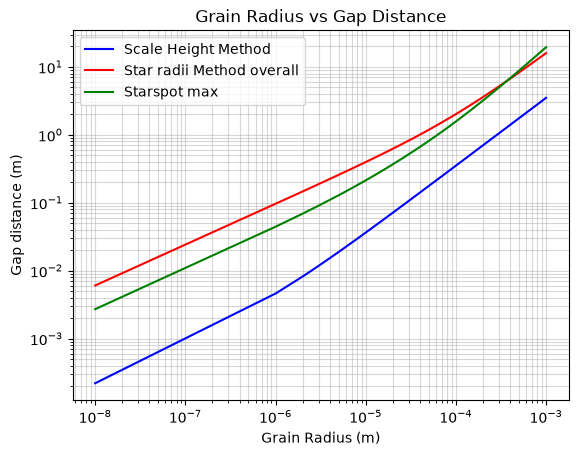

d range for scale height
0.00022003853744312203 3.5029968817796022
d range for global (brown dwarfs and exoplanet)
0.006056068195863661 15.974310964725657
d range for global (brown dwarfs only)
d range for starspots
0.0027117225837823998 19.484752211731088
587.1468926553672 43324854.29865863


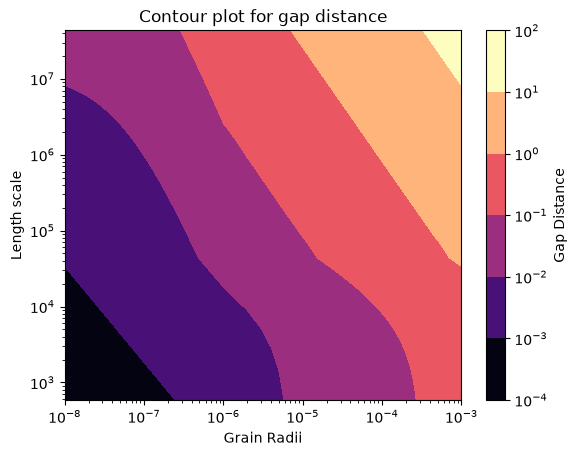

In [32]:
import numpy as np 
import import_ipynb 
import matplotlib.pyplot as plt

import matplotlib.colors as colors

%run lengthscales2.ipynb

In [33]:
L = np.linspace(10*1e3, 10*1e7, 1000)
a = np.linspace(1e-8,1e-3,1000)



B_0 = np.linspace(1e-3,1e-1, 1000)
M = 9.27*1e-26 
v_0 = 5


d = np.linspace(1e-3, 1e-2, 1000)
mu = 1.5*1e-3
mu_0 = 4*np.pi *10**-7
t_0 = 10


In [34]:
def phi(mu, mu_0): 
    return (mu - mu_0)/(mu + 2*mu_0)


phi = phi(mu, mu_0)

In [35]:
def omega(a,phi,B,M,mu_0,v_0,lambda_0,d,t_0,x):
    return (((8*np.pi*a**3 *phi* B**2)/(M*mu_0 * v_0**2))+ (768*a**6 * phi**2 * B**2 * np.pi**3 * lambda_0 **2)/(d**3 * M * v_0 **2 * mu_0 * x))**(1/2) * 1/t_0

In [36]:
x = np.linspace(780* 1e-9, 1e-3, 1000)

B = 1e-1 

a = 1e-3 
d = 1e-3 
lambda_0 = 1e-3

w = omega(a,phi,B,M,mu_0,v_0,lambda_0,d,t_0,x)

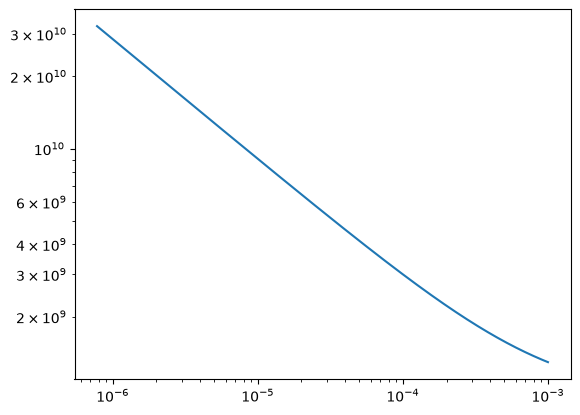

In [37]:
plt.loglog(x,w)

In [38]:
'''3 November 2026''' 

'3 November 2026'

In [39]:
import numpy as np 
import matplotlib.pyplot as plt
%run ranges_of_parameters.ipynb

In [40]:
'''Define magnetic moment''' 
def phi(mu, mu_0): 
    return (mu - mu_0)/(mu + 2*mu_0)


phi_val = phi(mu, mu_0)

def mag_mom(phi,a,mu_0,B):
    return(4*np.pi*a**3 * phi * B * mu_0**-1)


mag_mom_val_min = mag_mom(phi_val,a_min,mu_0, B_min)

mag_mom_val_max = mag_mom(phi_val, a_max, mu_0, B_max)

In [41]:
def omega_min(m,B,M,L): 
    return np.sqrt(2*m*B* M**-1) * (L**-1)


omega_min_val_1 = omega_min(mag_mom_val_min, B_min, M, L_max)



In [42]:
def omega_max(m,B,M,L, mu_0,d): 
    return np.sqrt(2*m*B* M**-1) * (L**-1) + np.sqrt((12 * mu_0)/(d**5 * np.pi * M)) * m



omega_max_val_1 = omega_max(mag_mom_val_min, B_min, M, L_max, mu_0,d_min)


print(omega_min_val_1, omega_max_val_1)


1.4669982927998417e-07 0.002269957755264439


In [43]:
omega_min_val_2 = omega_min(mag_mom_val_max, B_max, M, L_min)
omega_max_val_2 = omega_max(mag_mom_val_max, B_max, M, L_min, mu_0,d_max)

print(omega_min_val_2, omega_max_val_2)

4639055.928826091 717781918396.5104


In [44]:
def time(w): 
    return 2*np.pi / w 



min_time_1 = time(omega_min_val_1)
max_time_1 = time(omega_max_val_1)
min_time_2 = time(omega_min_val_2) 
max_time_2 = time(omega_max_val_2)



print('The variations go from ' + str(min_time_1) + ' seconds to ' +  str(max_time_2) + ' seconds')

The variations go from 42830215.536159925 seconds to 8.75361324400023e-12 seconds


In [58]:
'''4/11/2026'''

%run ranges_of_parameters.ipynb
import numpy as np
'''Contour plots'''

B_1 = 1e-3 
B_2 = 1e-2 
B_3 = 1e-1

d1 = 1e-3 
d2 = 1e-2 

phi_val = phi(mu, mu_0)


In [ ]:
'''for m^ = 1'''


def omega(B,M, L, a, phi, mu_0):
    return np.sqrt(2*B/M) * 1/L * np.sqrt(4*np.pi *a**3 * phi* B/mu_0)



def omega_f(B,M, L, a, phi, mu_0, d): 
    return np.sqrt(2*B/M) * 1/L * np.sqrt(4*np.pi *a**3 * phi* B/mu_0) + np.sqrt(12*mu_0/(d**5 * np.pi * M) * 4*np.pi * a**3 *phi * B * mu_0 **-1)




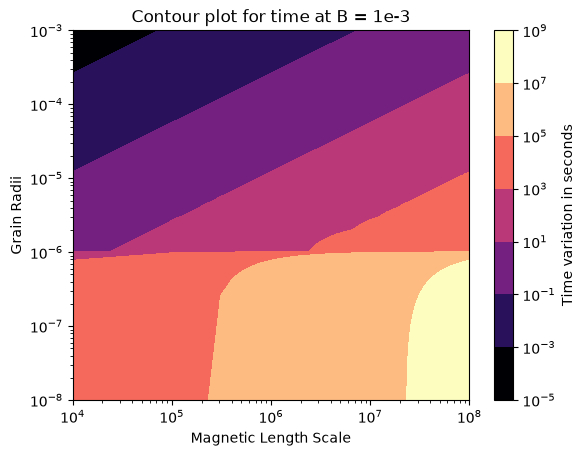

In [67]:
[x,y] = np.meshgrid(L, a)
z = 2*np.pi/ (omega(B_1, M, x, y, phi_val, mu_0))


plt.title('Contour plot for time at B = 1e-3')

plt.contourf(x,y,z, norm = colors.LogNorm(vmin = z.min(), vmax =  z.max()) ,cmap='magma')
plt.colorbar(label = 'Time variation in seconds')
plt.xlabel('Magnetic Length Scale')
plt.ylabel('Grain Radii')

plt.xscale('log')
plt.yscale('log')
plt.show()



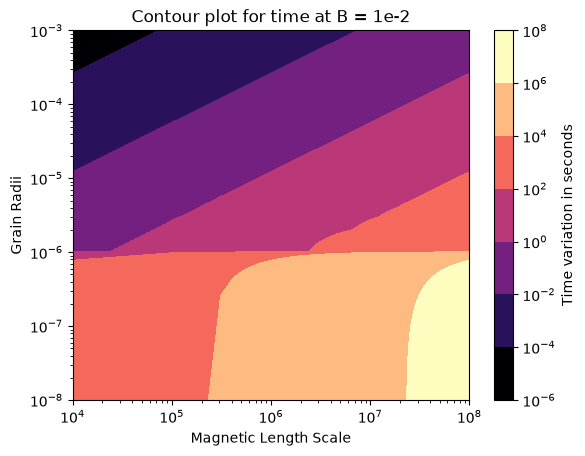

In [68]:
[x,y] = np.meshgrid(L, a)
z = 2*np.pi/ (omega(B_2, M, x, y, phi_val, mu_0))


plt.title('Contour plot for time at B = 1e-2')

plt.contourf(x,y,z, norm = colors.LogNorm(vmin = z.min(), vmax =  z.max()) ,cmap='magma')
plt.colorbar(label = 'Time variation in seconds')
plt.xlabel('Magnetic Length Scale')
plt.ylabel('Grain Radii')

plt.xscale('log')
plt.yscale('log')
plt.show()

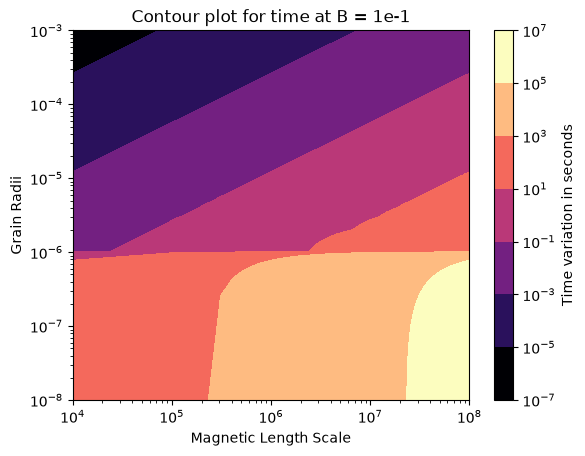

In [70]:
[x,y] = np.meshgrid(L, a)
z = 2*np.pi/ (omega(B_3, M, x, y, phi_val, mu_0))


plt.title('Contour plot for time at B = 1e-1')

plt.contourf(x,y,z, norm = colors.LogNorm(vmin = z.min(), vmax =  z.max()) ,cmap='magma')
plt.colorbar(label = 'Time variation in seconds')
plt.xlabel('Magnetic Length Scale')
plt.ylabel('Grain Radii')

plt.xscale('log')
plt.yscale('log')
plt.show()

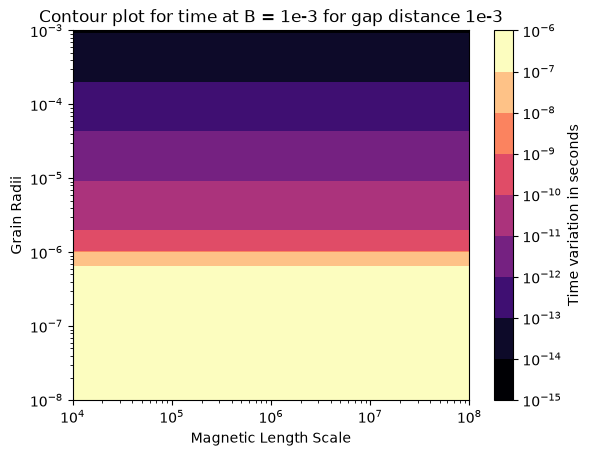

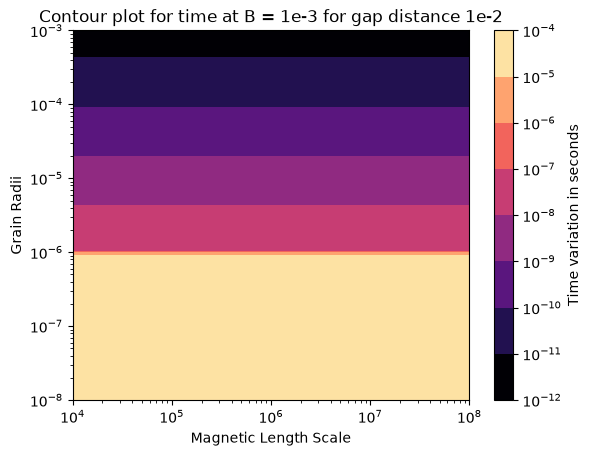

In [72]:
[x,y] = np.meshgrid(L, a)
z = 2*np.pi/ (omega_f(B_1, M, x, y, phi_val, mu_0, d1))


plt.title('Contour plot for time at B = 1e-3 for gap distance 1e-3')

plt.contourf(x,y,z, norm = colors.LogNorm(vmin = z.min(), vmax =  z.max()) ,cmap='magma')
plt.colorbar(label = 'Time variation in seconds')
plt.xlabel('Magnetic Length Scale')
plt.ylabel('Grain Radii')

plt.xscale('log')
plt.yscale('log')
plt.show()

[x,y] = np.meshgrid(L, a)
z = 2*np.pi/ (omega_f(B_1, M, x, y, phi_val, mu_0, d2))


plt.title('Contour plot for time at B = 1e-3 for gap distance 1e-2')

plt.contourf(x,y,z, norm = colors.LogNorm(vmin = z.min(), vmax =  z.max()) ,cmap='magma')
plt.colorbar(label = 'Time variation in seconds')
plt.xlabel('Magnetic Length Scale')
plt.ylabel('Grain Radii')

plt.xscale('log')
plt.yscale('log')
plt.show()